In [1]:
# ==========================================
# CELL 1: Setup, Dataset Creation & Download
# ==========================================
!pip install -q gradio

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import gradio as gr
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score, f1_score, ConfusionMatrixDisplay

# Calculate Sun Elevation & Azimuth (Latitude 18.5° N)
def sun_position(day_of_year, hour, lat=18.5):
    decl = np.radians(23.45 * np.sin(np.radians(360 / 365 * (284 + day_of_year))))
    w = np.radians(15 * (hour - 12))
    phi = np.radians(lat)
    sin_el = np.sin(phi) * np.sin(decl) + np.cos(phi) * np.cos(decl) * np.cos(w)
    el = np.degrees(np.arcsin(np.clip(sin_el, -1, 1)))
    cos_az = (np.sin(decl) - np.sin(np.radians(el)) * np.sin(phi)) / (np.cos(np.radians(el)) * np.cos(phi) + 1e-9)
    az = np.degrees(np.arccos(np.clip(cos_az, -1, 1)))
    az = np.where(w > 0, 360 - az, az)
    return el, az

# Generate 1-Year Hourly Daylight Dataset
rng = np.random.default_rng(42)
days, hours = np.meshgrid(np.arange(1, 366), np.arange(6, 19), indexing="ij")
day, hour = days.ravel(), hours.ravel()
month = (pd.to_datetime("2025-01-01") + pd.to_timedelta(day - 1, unit="D")).month.to_numpy()

month_cloud = np.array([10, 10, 15, 18, 28, 70, 82, 80, 68, 35, 15, 10])
cloud = np.clip(month_cloud[month - 1] + rng.normal(0, 18, 365)[day - 1] + rng.normal(0, 10, day.size), 0, 100)
temp = 24 + 5 * np.sin(2 * np.pi * (day - 44) / 365) + 7 * np.sin(np.pi * (hour - 8) / 12) - 0.05 * cloud + rng.normal(0, 1, day.size)
humidity = np.clip(30 + 0.6 * cloud - 0.8 * (temp - 25) + rng.normal(0, 5, day.size), 15, 100)
wind = rng.gamma(3, 1.4, day.size) + 3 * np.isin(month, [6, 7, 8, 9])

el, az = sun_position(day, hour)
keep = el > 2
day, hour, cloud, temp, humidity, wind, el, az = [a[keep] for a in (day, hour, cloud, temp, humidity, wind, el, az)]

sin_el = np.sin(np.radians(el))
ghi = np.clip(1000 * (sin_el ** 1.15) * (1 - 0.75 * (cloud / 100) ** 3.4), 0, None)
direct_share = 0.88 * (1 - cloud / 100) ** 1.3
dni = np.clip(ghi * direct_share / sin_el, 0, 950)
diffuse = ghi * (1 - direct_share)

beta = np.radians(18.5)
cos_inc = np.clip(sin_el * np.cos(beta) + np.cos(np.radians(el)) * np.sin(beta) * np.cos(np.radians(az - 180)), 0, 1)

def calc_power(poa):
    t_cell = temp + 0.03 * poa
    return np.clip(5 * (poa / 1000) * (1 - 0.004 * (t_cell - 25)) * 0.9 * (1 + rng.normal(0, 0.02, poa.size)), 0, None)

power_tracker = calc_power(dni + diffuse)
power_fixed = calc_power(dni * cos_inc + diffuse * (1 + np.cos(beta)) / 2)
track_needed = ((cloud < 70) & (el >= 15) & (wind < 12)).astype(int)

df = pd.DataFrame({
    "day_of_year": day, "hour": hour, "temperature": temp, "humidity": humidity,
    "cloud_cover": cloud, "wind_speed": wind, "sun_elevation": el, "sun_azimuth": az,
    "power_kw": power_tracker, "fixed_power_kw": power_fixed, "track_needed": track_needed
}).round(2)

# Clean missing values & outliers
df["humidity"] = df["humidity"].fillna(df["humidity"].median())
df.to_csv("solar_tracking_dataset.csv", index=False)
print(f"Dataset ready: {df.shape[0]} rows | Tracker gives {(df['power_kw'].sum()/df['fixed_power_kw'].sum()-1)*100:.1f}% more energy!")

try:
    from google.colab import files
    files.download("solar_tracking_dataset.csv")
except ImportError:
    pass

df.head()

Dataset ready: 4317 rows | Tracker gives 29.4% more energy!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,day_of_year,hour,temperature,humidity,cloud_cover,wind_speed,sun_elevation,sun_azimuth,power_kw,fixed_power_kw,track_needed
0,1,7,18.18,32.02,8.05,6.59,5.85,116.66,2.40,0.68,0
1,1,8,20.28,40.42,7.26,5.76,18.20,122.95,3.08,1.60,1
2,1,9,22.36,38.78,17.51,4.32,29.55,131.57,3.09,2.21,1
3,1,10,24.58,45.77,23.93,4.55,39.19,143.57,3.32,2.78,1
4,1,11,25.38,39.81,15.60,3.13,45.98,159.95,3.51,3.20,1


--- Power Prediction (kW) ---
Linear Regression | R2: 0.909 | MAE: 0.231 kW
Random Forest     | R2: 0.994 | MAE: 0.057 kW

--- Tracking Mode Decision ---
Logistic Regression | Accuracy: 0.822 | F1: 0.867
Random Forest       | Accuracy: 0.999 | F1: 0.999


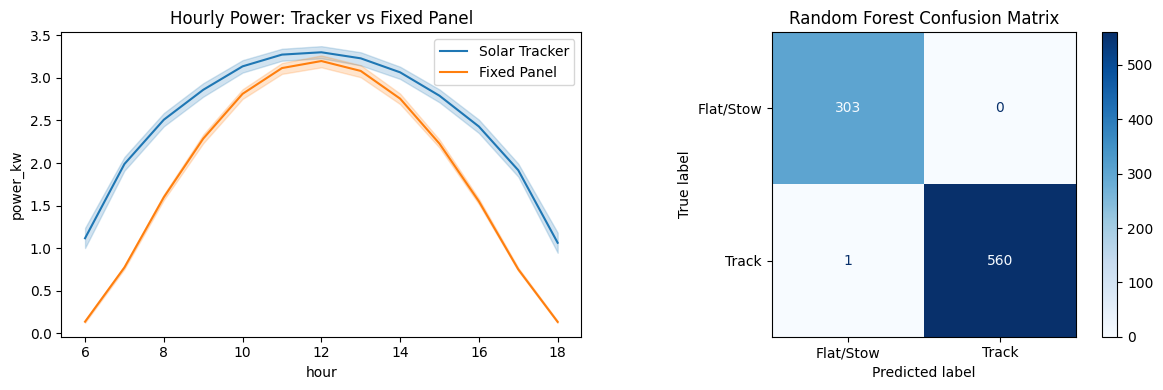

In [2]:
# ==========================================
# CELL 2: Train & Compare Models
# ==========================================
FEATURES = ["hour", "day_of_year", "temperature", "humidity", "cloud_cover", "wind_speed", "sun_elevation", "sun_azimuth"]
X = df[FEATURES]
y_power = df["power_kw"]
y_track = df["track_needed"]

X_train, X_test, yp_train, yp_test, yt_train, yt_test = train_test_split(
    X, y_power, y_track, test_size=0.2, random_state=42, stratify=y_track
)

# 1. Power Prediction (Regression)
lr = LinearRegression().fit(X_train, yp_train)
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, yp_train)

print("--- Power Prediction (kW) ---")
print(f"Linear Regression | R2: {r2_score(yp_test, lr.predict(X_test)):.3f} | MAE: {mean_absolute_error(yp_test, lr.predict(X_test)):.3f} kW")
print(f"Random Forest     | R2: {r2_score(yp_test, rf_reg.predict(X_test)):.3f} | MAE: {mean_absolute_error(yp_test, rf_reg.predict(X_test)):.3f} kW")

# 2. Tracking Decision (Classification)
log_reg = Pipeline([("scale", StandardScaler()), ("m", LogisticRegression())]).fit(X_train, yt_train)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, yt_train)

print("\n--- Tracking Mode Decision ---")
print(f"Logistic Regression | Accuracy: {accuracy_score(yt_test, log_reg.predict(X_test)):.3f} | F1: {f1_score(yt_test, log_reg.predict(X_test)):.3f}")
print(f"Random Forest       | Accuracy: {accuracy_score(yt_test, rf_clf.predict(X_test)):.3f} | F1: {f1_score(yt_test, rf_clf.predict(X_test)):.3f}")

# Plot Tracker vs Fixed Power & Confusion Matrix
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=df, x="hour", y="power_kw", label="Solar Tracker", ax=ax[0])
sns.lineplot(data=df, x="hour", y="fixed_power_kw", label="Fixed Panel", ax=ax[0])
ax[0].set_title("Hourly Power: Tracker vs Fixed Panel")
ConfusionMatrixDisplay.from_estimator(rf_clf, X_test, yt_test, display_labels=["Flat/Stow", "Track"], cmap="Blues", ax=ax[1])
ax[1].set_title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [3]:
# ==========================================
# CELL 3: Save Models & Launch Web App
# ==========================================
final_power = RandomForestRegressor(n_estimators=100, random_state=42).fit(X, y_power)
final_mode = RandomForestClassifier(n_estimators=100, random_state=42).fit(X, y_track)
joblib.dump({"power": final_power, "mode": final_mode, "features": FEATURES}, "solar_models.joblib")

bundle = joblib.load("solar_models.joblib")

def predict_solar(day, hour, temp, humidity, cloud, wind):
    el, az = sun_position(day, hour)
    if el <= 2:
        return "Night / Sun Below Horizon: Park Panel", "-", "0.00 kW"
    row = pd.DataFrame([{
        "hour": hour, "day_of_year": day, "temperature": temp, "humidity": humidity,
        "cloud_cover": cloud, "wind_speed": wind, "sun_elevation": float(el), "sun_azimuth": float(az)
    }])[bundle["features"]]
    power = bundle["power"].predict(row)[0]
    track = bundle["mode"].predict(row)[0]
    if track == 1:
        return "TRACK THE SUN", f"Azimuth: {az:.0f}°, Tilt: {90 - el:.0f}°", f"{power:.2f} kW"
    return "KEEP FLAT / STOWED (Cloudy or High Wind)", "Tilt: 0° (Flat)", f"{power:.2f} kW"

demo = gr.Interface(
    fn=predict_solar,
    inputs=[
        gr.Slider(1, 365, value=120, step=1, label="Day of Year (1-365)"),
        gr.Slider(6, 18, value=12, step=1, label="Hour of Day (6-18)"),
        gr.Slider(10, 45, value=33, step=1, label="Temperature (°C)"),
        gr.Slider(15, 100, value=40, step=1, label="Humidity (%)"),
        gr.Slider(0, 100, value=10, step=1, label="Cloud Cover (%)"),
        gr.Slider(0, 25, value=4, step=1, label="Wind Speed (m/s)")
    ],
    outputs=[
        gr.Textbox(label="Tracker Decision"),
        gr.Textbox(label="Target Panel Angle"),
        gr.Textbox(label="Predicted Power Output")
    ],
    title="Smart Solar Tracking System",
    description="Predicts solar power output and decides whether the tracker should follow the sun.",
    examples=[[120, 12, 34, 35, 5, 4], [200, 12, 27, 85, 90, 8], [160, 15, 29, 70, 40, 15]]
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d3378f16d493e755e6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
